In [107]:
import os, sys
os.environ["JAVA_HOME"] = os.path.join(sys.prefix, "Library")
os.environ["PATH"] = os.path.join(sys.prefix, "Library", "bin") + os.pathsep + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

In [108]:
import pandas as pd
import numpy as np
import random
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import(
    Input,
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import os
from pathlib import Path
from PIL import Image, ImageFile
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
import pyspark
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "merged_dataset.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT
TRAIN_DIR = DATA_DIR / "Training Data"
TEST_DIR = DATA_DIR / "Testing Data"
VAL_DIR = DATA_DIR / "Validation Data"

OUTPUT_DIR = PROJECT_ROOT / "output"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = (180, 180)
BATCH_SIZE = 32
RANDOM_STATE = 42

CLASS_NAMES = [
    "Mountain",
    "Glacier",
    "Forest",
    "Desert",
    "Coast"
]



In [109]:
print("TRAIN_DIR:", TRAIN_DIR.resolve())
print("Contents:", [p.name for p in TRAIN_DIR.iterdir()])

TRAIN_DIR: C:\Users\Jesse-LeeWeeder\Training Data
Contents: ['Coast', 'Desert', 'Forest', 'Glacier', 'Mountain']


In [110]:
def count_images(directory):
    results = {}

    for category in CLASS_NAMES:
        category_path = directory / category

        if category_path.exists():
            image_count = len([
                file for file in category_path.iterdir()
                if file.is_file()
            ])

            results[category] = image_count

        else:
            results[category] = 0
    return results

train_counts = count_images(TRAIN_DIR)
val_counts = count_images(VAL_DIR)
test_counts = count_images(TEST_DIR)

image_distribution = pd.DataFrame({
    "Training": train_counts,
    "Validation": val_counts,
    "Testing": test_counts
})

print(image_distribution)

          Training  Validation  Testing
Mountain      2000         300      100
Glacier       2000         300      100
Forest        2000         300      100
Desert        2000         300      100
Coast         2000         300      100


In [111]:
data = pd.read_csv(DATA_DIR / "merged_dataset.csv")
data.head()

,rel_path,filename,label,original_split,extension,size_bytes,md5,width,height,mode,format,is_corrupt
0,Training Data/Coast/Coast-Train (1).jpeg,Coast-Train (1).jpeg,Coast,Training,.jpeg,6089,e764538413827d08d6b9291cc92fa7b1,275,183,RGB,JPEG,False
1,Training Data/Coast/Coast-Train (10).jpeg,Coast-Train (10).jpeg,Coast,Training,.jpeg,5898,2ebeaadf42a1566e6e9caedd233f323e,300,168,RGB,JPEG,False
2,Training Data/Coast/Coast-Train (100).jpeg,Coast-Train (100).jpeg,Coast,Training,.jpeg,12894,8f9c16e90f06b6d291e8596efcde63ca,275,183,RGB,JPEG,False
3,Training Data/Coast/Coast-Train (1000).jpeg,Coast-Train (1000).jpeg,Coast,Training,.jpeg,10087,429b4107b90f2daab4d9d1f1554ad966,275,183,RGB,JPEG,False
4,Training Data/Coast/Coast-Train (1001).jpeg,Coast-Train (1001).jpeg,Coast,Training,.jpeg,9286,877e7d1b3867359c84dd25c861c6cb24,300,168,RGB,JPEG,False


In [112]:
data.shape

(12000, 12)

In [113]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   rel_path        12000 non-null  str  
 1   filename        12000 non-null  str  
 2   label           12000 non-null  str  
 3   original_split  12000 non-null  str  
 4   extension       12000 non-null  str  
 5   size_bytes      12000 non-null  int64
 6   md5             12000 non-null  str  
 7   width           12000 non-null  int64
 8   height          12000 non-null  int64
 9   mode            12000 non-null  str  
 10  format          12000 non-null  str  
 11  is_corrupt      12000 non-null  bool 
dtypes: bool(1), int64(3), str(8)
memory usage: 2.5 MB


In [114]:
data.isnull().sum()

rel_path          0
filename          0
label             0
original_split    0
extension         0
size_bytes        0
md5               0
width             0
height            0
mode              0
format            0
is_corrupt        0
dtype: int64

In [115]:
data.duplicated().sum()

np.int64(0)

In [116]:
label_conflicts = (
    data.groupby("md5")["label"]
    .nunique()
)

conflicting_hashes = label_conflicts[
    label_conflicts > 1
].index

conflicts = data[
    data["md5"].isin(conflicting_hashes)
].sort_values("md5")

len(conflicting_hashes)

print(conflicts[
    ["filename", "label", "original_split", "md5"]
    ])

                        filename     label original_split  \
5236     Forest-Train (310).jpeg    Forest       Training   
8365        Mountain (3341).jpeg  Mountain       Training   
6965   Glacier-Train (1868).jpeg   Glacier       Training   
8187        Mountain (3163).jpeg  Mountain       Training   
9709        Mountain (4685).jpeg  Mountain       Training   
4179     Forest-Train (116).jpeg    Forest       Training   
8543        Mountain (3519).jpeg  Mountain       Training   
5490      Forest-Train (54).jpeg    Forest       Training   
9062        Mountain (4038).jpeg  Mountain       Training   
9652        Mountain (4628).jpeg  Mountain       Training   
10803    Forest-Valid (282).jpeg    Forest     Validation   
5676     Forest-Train (707).jpeg    Forest       Training   
9835        Mountain (4811).jpeg  Mountain       Training   
6959   Glacier-Train (1862).jpeg   Glacier       Training   
10037     Coast-Valid (132).jpeg     Coast     Validation   
3726     Desert-Train (7

In [117]:
data_clean = data.copy()

label_conflicts = (
    data_clean.groupby("md5")["label"].nunique()
)

conflicting_hashes = label_conflicts[
    label_conflicts > 1
].index

data_clean = data_clean[
    ~data_clean["md5"].isin(conflicting_hashes)
].copy()

split_priority = {
    "Training": 0,
    "Validation": 1,
    "Testing": 2
}

data_clean["split_priority"] = data_clean["original_split"].map(split_priority)

data_clean = data_clean.sort_values(by=["split_priority"])

data_clean = data_clean.drop(columns=["split_priority"])

print("Original", len(data))
print("Cleaned", len(data_clean))

Original 12000
Cleaned 11976


In [118]:
before = len(data_clean)

data_clean = data_clean.drop_duplicates(
    subset="md5",
    keep="first"
).copy()

data_clean.reset_index(drop=True, inplace=True)


Checking Image Quality and removing corrupt or missing images

In [119]:
missing_files = []
corrupt_files = []

for index, row in data_clean.iterrows():
    image_path = PROJECT_ROOT / row["rel_path"]

    if not image_path.exists():
        missing_files.append(row["rel_path"])
        continue

    try:
        with Image.open(image_path) as img:
            img.verify()
    except Exception:
        corrupt_files.append(row["rel_path"])

print("Missing files:", len(missing_files))
print("Corrupt files:", len(corrupt_files))

Missing files: 0
Corrupt files: 0


In [120]:
invalid_files = missing_files + corrupt_files

data_clean = data_clean[
    ~data_clean["rel_path"].isin(invalid_files)
].copy()

data_clean.reset_index(drop=True, inplace=True)

print("Final dataset shape:", data_clean.shape)

Final dataset shape: (11657, 12)


Checking Image dimensions and colour modes

In [121]:
print("Image Dimensions:")
print(data_clean[["width", "height"]].describe())

print("\nColour Modes")
print(data_clean["mode"].value_counts())

print("\nImage Formats")
print(data_clean["format"].value_counts())

Image Dimensions:
              width        height
count  11657.000000  11657.000000
mean     272.104830    189.555117
std       40.600775     33.030342
min      133.000000     94.000000
25%      262.000000    173.000000
50%      275.000000    183.000000
75%      291.000000    193.000000
max      537.000000    347.000000

Colour Modes
mode
RGB    11657
Name: count, dtype: int64

Image Formats
format
JPEG    11657
Name: count, dtype: int64


Preparation

In [122]:
data_clean["image_path"] = data_clean["rel_path"].apply(lambda x: PROJECT_ROOT / x)



encoding class names

In [123]:
class_names = ["Mountain", "Glacier", "Forest", "Desert", "Coast"]

label_mapping = {
    label: index for index, label in enumerate(class_names)
}

data_clean["encoded_labels"] = data_clean["label"].map(label_mapping)
print(label_mapping)

{'Mountain': 0, 'Glacier': 1, 'Forest': 2, 'Desert': 3, 'Coast': 4}


Creating image-loading pipeline

In [124]:
data_clean["image_path"] = data_clean["image_path"].apply(
    lambda x: str(x)
)


In [125]:
import os, subprocess, pyspark
print("PySpark:", pyspark.__version__)
print("JAVA_HOME:", os.environ.get("JAVA_HOME"))
print(subprocess.run(["java", "-version"], capture_output=True, text=True, shell=True).stderr)

PySpark: 4.2.0
JAVA_HOME: c:\Users\Jesse-LeeWeeder\.conda\envs\spark_env\Library
openjdk version "17.0.21.1" 2026-11-17 LTS
OpenJDK Runtime Environment Zulu17.70+201-CA (build 17.0.21.1+2-LTS)
OpenJDK 64-Bit Server VM Zulu17.70+201-CA (build 17.0.21.1+2-LTS, mixed mode, sharing)



In [126]:
def load_image(image_path, label):
    image = tf.io.read_file(image_path)

    image = tf.io.decode_jpeg(
        image,
        channels = 3
    )

    image = tf.image.resize(
        image,
        IMAGE_SIZE
    )

    image = image / 255.0

    return image, label

def create_dataset(split, shuffle=False):
    split_data = data_clean[
        data_clean["original_split"] == split
    ]

    image_paths = split_data["image_path"].values
    labels = split_data["encoded_labels"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(split_data),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )  

    dataset = dataset.batch(BATCH_SIZE)  
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_dataset = create_dataset("Training", shuffle=True)
val_dataset = create_dataset("Validation")
test_dataset = create_dataset("Testing")

## Exploratory Data Analysis

In [127]:
spark = SparkSession.builder \
    .appName("Scenery_Image_EDA") \
    .getOrCreate()

print("Spark Version:", spark.version)

Spark Version: 4.2.0


In [128]:
eda_data = data_clean[
    [
        "filename",
        "label",
        "original_split",
        "width",
        "height",
        "size_bytes",
        "format",
        "mode"
    ]
].copy()

spark_data = spark.createDataFrame(eda_data)

spark_data.printSchema()

spark_data.show(5, truncate=False)

print("Total Images: ", spark_data.count())

root
 |-- filename: string (nullable = true)
 |-- label: string (nullable = true)
 |-- original_split: string (nullable = true)
 |-- width: long (nullable = true)
 |-- height: long (nullable = true)
 |-- size_bytes: long (nullable = true)
 |-- format: string (nullable = true)
 |-- mode: string (nullable = true)

+-----------------------+-----+--------------+-----+------+----------+------+----+
|filename               |label|original_split|width|height|size_bytes|format|mode|
+-----------------------+-----+--------------+-----+------+----------+------+----+
|Coast-Train (1).jpeg   |Coast|Training      |275  |183   |6089      |JPEG  |RGB |
|Coast-Train (10).jpeg  |Coast|Training      |300  |168   |5898      |JPEG  |RGB |
|Coast-Train (100).jpeg |Coast|Training      |275  |183   |12894     |JPEG  |RGB |
|Coast-Train (1000).jpeg|Coast|Training      |275  |183   |10087     |JPEG  |RGB |
|Coast-Train (1001).jpeg|Coast|Training      |300  |168   |9286      |JPEG  |RGB |
+---------------------

c:\Users\Jesse-LeeWeeder\.conda\envs\spark_env\Lib\site-packages\pyspark\sql\pandas\conversion.py:659: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Jesse-LeeWeeder\.conda\envs\spark_env\Lib\site-packages\pyspark\sql\pandas\conversion.py:936: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Total Images:  11657


In [129]:
spark_data.describe(
    "width",
    "height",
    "size_bytes"
).show()

+-------+------------------+------------------+------------------+
|summary|             width|            height|        size_bytes|
+-------+------------------+------------------+------------------+
|  count|             11657|             11657|             11657|
|   mean|272.10482971605046|189.55511709702324| 9463.482113751394|
| stddev| 40.60077523138882| 33.03034216504956|3459.6692790092193|
|    min|               133|                94|              1691|
|    max|               537|               347|             32618|
+-------+------------------+------------------+------------------+



Analysing class distribution

In [130]:
class_dist = spark_data.groupBy("label") \
    .count() \
    .orderBy(F.desc("count"))

class_dist.show()

+--------+-----+
|   label|count|
+--------+-----+
|   Coast| 2395|
| Glacier| 2341|
|  Forest| 2330|
|  Desert| 2313|
|Mountain| 2278|
+--------+-----+



In [131]:
dist_percent = spark_data.count()

class_dist = class_dist.withColumn(
    "percentage",
    F.round((F.col("count") / dist_percent) * 100, 2)
)

class_dist.show()

+--------+-----+----------+
|   label|count|percentage|
+--------+-----+----------+
|   Coast| 2395|     20.55|
| Glacier| 2341|     20.08|
|  Forest| 2330|     19.99|
|  Desert| 2313|     19.84|
|Mountain| 2278|     19.54|
+--------+-----+----------+



c:\Users\Jesse-LeeWeeder\.conda\envs\spark_env\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


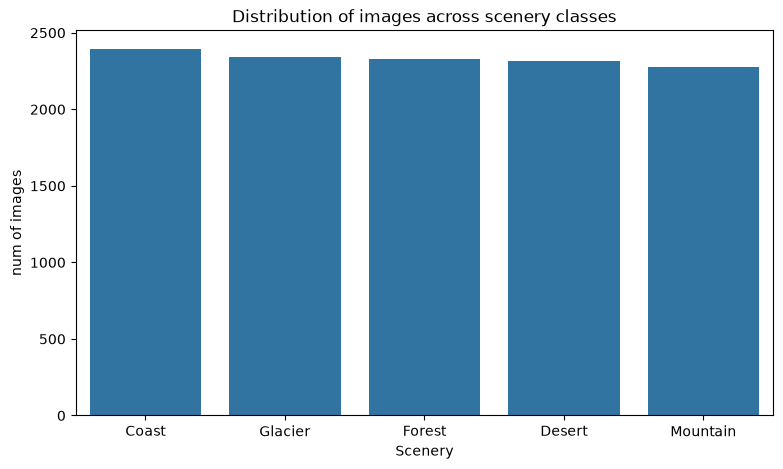

In [132]:
class_pd = class_dist.toPandas()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=class_pd,
    x="label",
    y="count"
)

plt.title("Distribution of images across scenery classes")
plt.xlabel("Scenery")
plt.ylabel("num of images")
plt.tight_layout
plt.show()

Investigating the distribution across the original splits

In [133]:
split_dist = spark_data.groupBy("original_split") \
    .count() \
    .orderBy("original_split")

split_dist.show()

split_dist = split_dist.withColumn(
    "percentage",
    F.round(
        (F.col("count") / dist_percent) * 100, 2
    )
)

split_dist.show()

+--------------+-----+
|original_split|count|
+--------------+-----+
|       Testing|  445|
|      Training| 9771|
|    Validation| 1441|
+--------------+-----+

+--------------+-----+----------+
|original_split|count|percentage|
+--------------+-----+----------+
|       Testing|  445|      3.82|
|      Training| 9771|     83.82|
|    Validation| 1441|     12.36|
+--------------+-----+----------+



c:\Users\Jesse-LeeWeeder\.conda\envs\spark_env\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


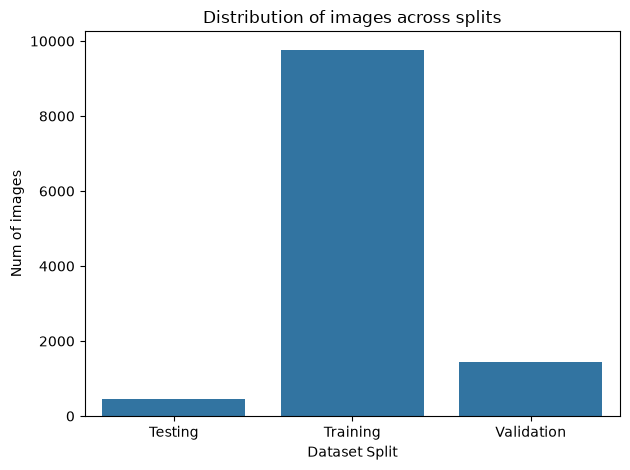

In [134]:
split_pd = split_dist.toPandas()

plt.Figure(figsize=(8, 5))

sns.barplot(
    data=split_pd,
    x="original_split",
    y="count"
)

plt.title("Distribution of images across splits")
plt.xlabel("Dataset Split")
plt.ylabel("Num of images")
plt.tight_layout()
plt.show()

Investigating the relationships between image dimensions

In [135]:
data_dimensions = spark_data.withColumn(
    "aspect_ration",
    F.col("width") / F.col("height")
)

data_dimensions.select(
    F.round(F.avg("aspect_ration"), 3).alias("average_aspect_ratio"),
    F.round(F.min("aspect_ration"), 3).alias("minimum_aspect_ratio"),
    F.round(F.max("aspect_ration"), 3).alias("maximum_aspect_ratio")
).show()

+--------------------+--------------------+--------------------+
|average_aspect_ratio|minimum_aspect_ratio|maximum_aspect_ratio|
+--------------------+--------------------+--------------------+
|               1.504|               0.418|               5.713|
+--------------------+--------------------+--------------------+



In [136]:
data_dimensions = data_dimensions.withColumn(
    "orientation",
    F.when(F.col("width") > F.col("height"), "Landscape")
    .when(F.col("width") < F.col("height"), "Portrait")
    .otherwise("Square")
)

image_orientation = data_dimensions.groupBy(
    "orientation"
).count().orderBy(F.desc("count"))

image_orientation.show()

+-----------+-----+
|orientation|count|
+-----------+-----+
|  Landscape|10147|
|   Portrait| 1228|
|     Square|  282|
+-----------+-----+



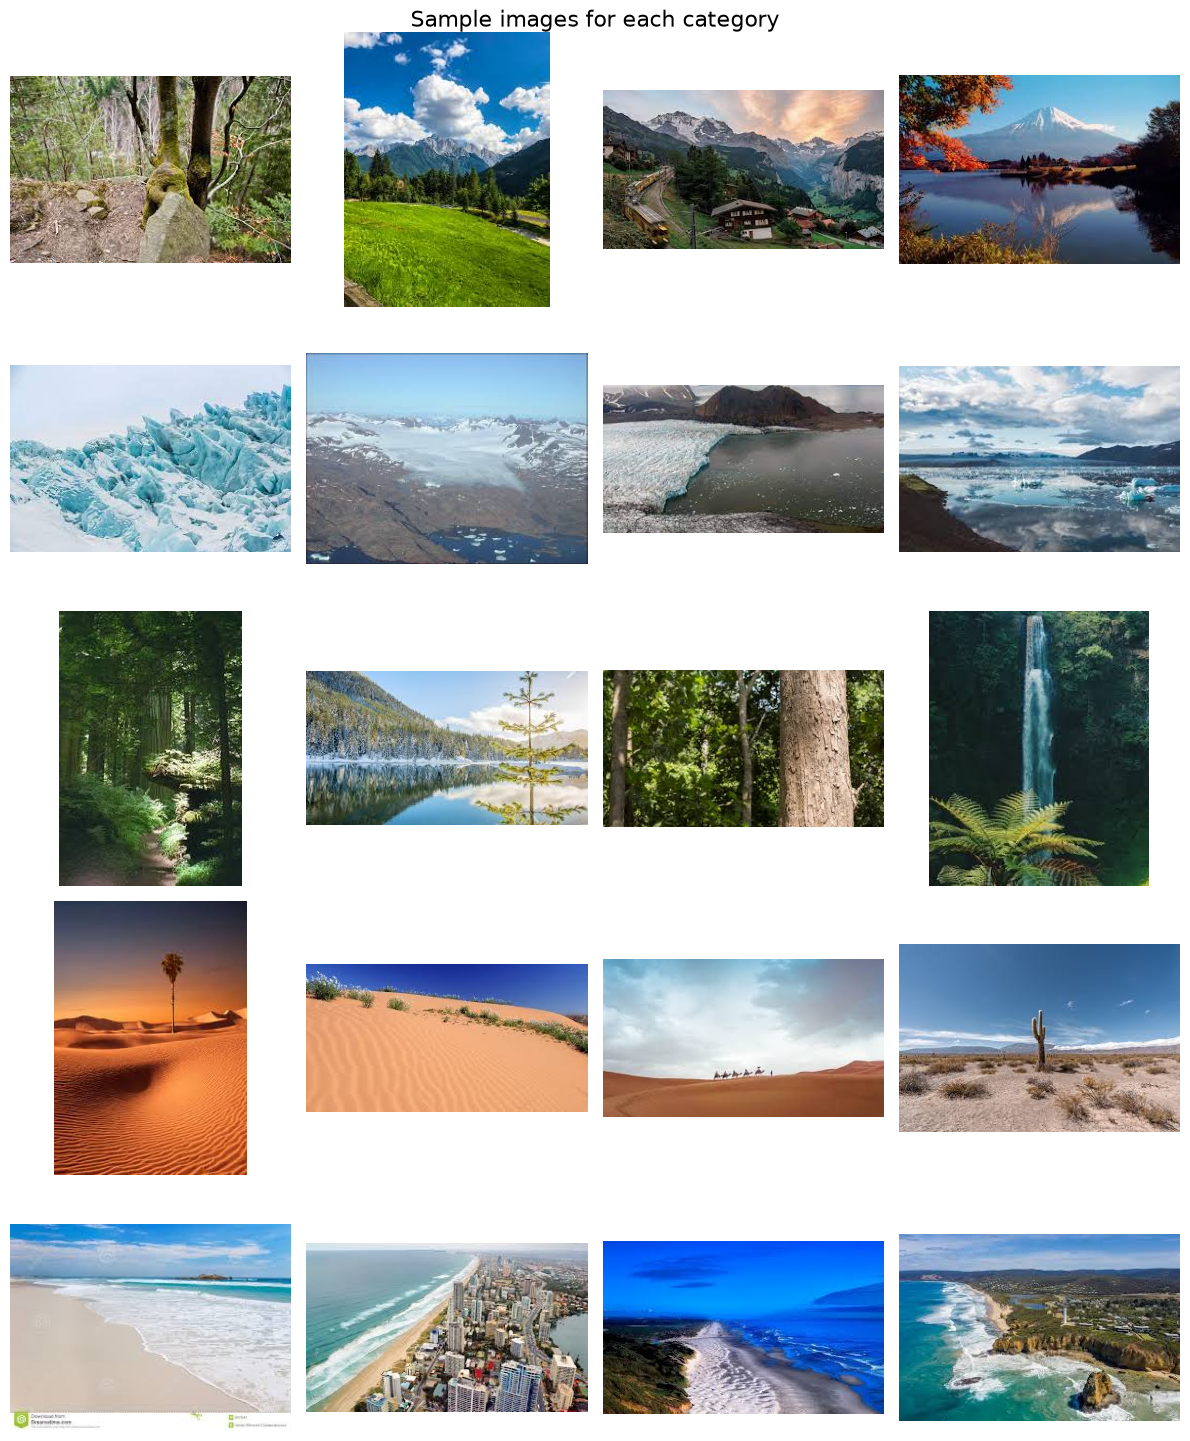

In [137]:
class_names = ["Mountain", "Glacier", "Forest", "Desert", "Coast"]

fig, axes = plt.subplots(5, 4, figsize=(12, 15))

for row, class_names in enumerate(class_names):
    class_images = data_clean[
        data_clean["label"] == class_names
    ]

    samples = class_images.sample(
        n=4,
        random_state = 42
    )

    for col, (_, image_row) in enumerate(samples.iterrows()):
        image = Image.open(image_row["image_path"]).convert("RGB")

        axes[row, col].imshow(image)
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_ylabel(
                class_names,
                fontsize = 12
            )

plt.suptitle("Sample images for each category", fontsize=16)
plt.tight_layout()
plt.show()

## Model Creation

In [138]:
cnn_model = Sequential([
    Input(shape=(180, 180, 3)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(5, activation="softmax")
])

cnn_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,405 (431.27 KB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

In [139]:
cnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Overfitting Reduction

In [140]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

Model Training

In [143]:
results = cnn_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=[
        early_stopping,
        reduce_lr
    ],
    verbose=1
)

Epoch 1/20
306/306 ━━━━━━━━━━━━━━━━━━━━ 66s 214ms/step - accuracy: 0.6998 - loss: 0.7857 - val_accuracy: 0.6801 - val_loss: 0.8363 - learning_rate: 0.0010
Epoch 2/20
306/306 ━━━━━━━━━━━━━━━━━━━━ 70s 227ms/step - accuracy: 0.7136 - loss: 0.7554 - val_accuracy: 0.6600 - val_loss: 0.8599 - learning_rate: 0.0010
Epoch 3/20
306/306 ━━━━━━━━━━━━━━━━━━━━ 100s 326ms/step - accuracy: 0.7112 - loss: 0.7637 - val_accuracy: 0.6322 - val_loss: 0.9019 - learning_rate: 0.0010
Epoch 4/20
306/306 ━━━━━━━━━━━━━━━━━━━━ 73s 240ms/step - accuracy: 0.7256 - loss: 0.7258 - val_accuracy: 0.6891 - val_loss: 0.8144 - learning_rate: 5.0000e-04
Epoch 5/20
306/306 ━━━━━━━━━━━━━━━━━━━━ 199s 649ms/step - accuracy: 0.7297 - loss: 0.7103 - val_accuracy: 0.6856 - val_loss: 0.8191 - learning_rate: 5.0000e-04
Epoch 6/20
306/306 ━━━━━━━━━━━━━━━━━━━━ 196s 638ms/step - accuracy: 0.7329 - loss: 0.7080 - val_accuracy: 0.6981 - val_loss: 0.7993 - learning_rate: 5.0000e-04
Epoch 7/20
306/306 ━━━━━━━━━━━━━━━━━━━━ 79s 256ms/step 